# Лабораторная 4 Проверка гипотез и сравнение групп

**Иноземцев Сергей Викторович · ЕТ-216**

Все части работы собраны в одном ноутбуке. Выполнять сверху вниз в новом ядре. Таблицы находятся рядом; графики отображаются только внутри ноутбука. Источник заданий: [курс edu.susu.ru](https://edu.susu.ru/course/view.php?id=218588).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 25)
pd.set_option('display.max_rows', 25)
sns.set_theme(style='whitegrid', font='DejaVu Sans')
plt.rcParams.update({'figure.figsize': (9, 5), 'figure.dpi': 110})
DATA = Path('lab4') if Path('lab4').is_dir() else Path('.')

def show(name=None):
    """Показать график в ноутбуке без создания внешних файлов."""
    plt.tight_layout()
    plt.show()
    plt.close('all')


## A Новорождённые и проверка гипотез

### Постановка и выбор методов
Выполняются прикреплённые задания «Гипотезы», «Т-тесты» и бонус «Проверка нормальности». Сравниваются независимые группы, поэтому используется двусторонний t-тест Уэлча (equal_var=False), не требующий равенства дисперсий. H0: средние равны; H1: средние различаются; α=0,05. Для серии сравнений дополнительно приведена поправка Holm. Неотклонение H0 не доказывает равенство распределений. Номер учащегося и код профиля не считаются измеряемыми психологическими шкалами.

### Новорождённые Проверка структуры и единиц

In [2]:
birth = pd.read_excel(DATA / 'Пренатальная диагностика.xlsx', sheet_name='исходные данные')
display(birth.head())
display(birth.isna().sum())
display(birth['pol(1-м, 0-д)'].value_counts().rename(index={0: 'девочки', 1: 'мальчики'}))
assert set(birth['pol(1-м, 0-д)'].unique()) <= {0, 1}
birth['ИМТ'] = birth.ves / 1000 / (birth.rost / 100) ** 2
num = [c for c in birth.select_dtypes('number').columns if c != 'pol(1-м, 0-д)']
descr = birth[num].describe().T
descr['range'] = birth[num].max() - birth[num].min()
descr['median'] = birth[num].median()
display(descr)

,vozrast,gr-dni,ctr,nt,rost,ves,"pol(1-м, 0-д)"
0,18,70,61,1.3,48,3100,0
1,22,72,50,0.9,50,3400,0
2,29,73,45,0.9,53,3500,1
3,28,74,47,1.1,50,3490,1
4,31,74,46,1.3,53,3590,0


vozrast          0
gr-dni           0
ctr              0
nt               0
rost             0
ves              0
pol(1-м, 0-д)    0
dtype: int64

pol(1-м, 0-д)
мальчики    577
девочки     473
Name: count, dtype: int64

,count,mean,std,min,25%,50%,75%,max,range,median
vozrast,1050.0,28.681905,5.406432,16.000000,25.000000,28.000000,33.000000,45.000000,29.000000,28.000000
gr-dni,1050.0,88.764762,6.314969,70.000000,84.000000,88.000000,93.000000,108.000000,38.000000,88.000000
ctr,1050.0,64.125714,10.449999,45.000000,56.000000,64.000000,72.000000,85.000000,40.000000,64.000000
nt,1050.0,1.337333,0.397701,0.300000,1.100000,1.300000,1.600000,2.800000,2.500000,1.300000
rost,1050.0,51.698095,2.087069,45.000000,50.000000,52.000000,53.000000,60.000000,15.000000,52.000000
ves,1050.0,3435.779048,399.315445,2410.000000,3150.000000,3430.000000,3700.000000,5040.000000,2630.000000,3430.000000
ИМТ,1050.0,12.829898,1.017828,8.686365,12.110727,12.801384,13.417916,18.117451,9.431086,12.801384


ИМТ рассчитан как масса в килограммах / рост в метрах²; исходные единицы — граммы и сантиметры. Здесь показатель используется только как учебный числовой признак, без медицинских заключений. Код пола бинарный и не проверяется на непрерывное нормальное распределение.

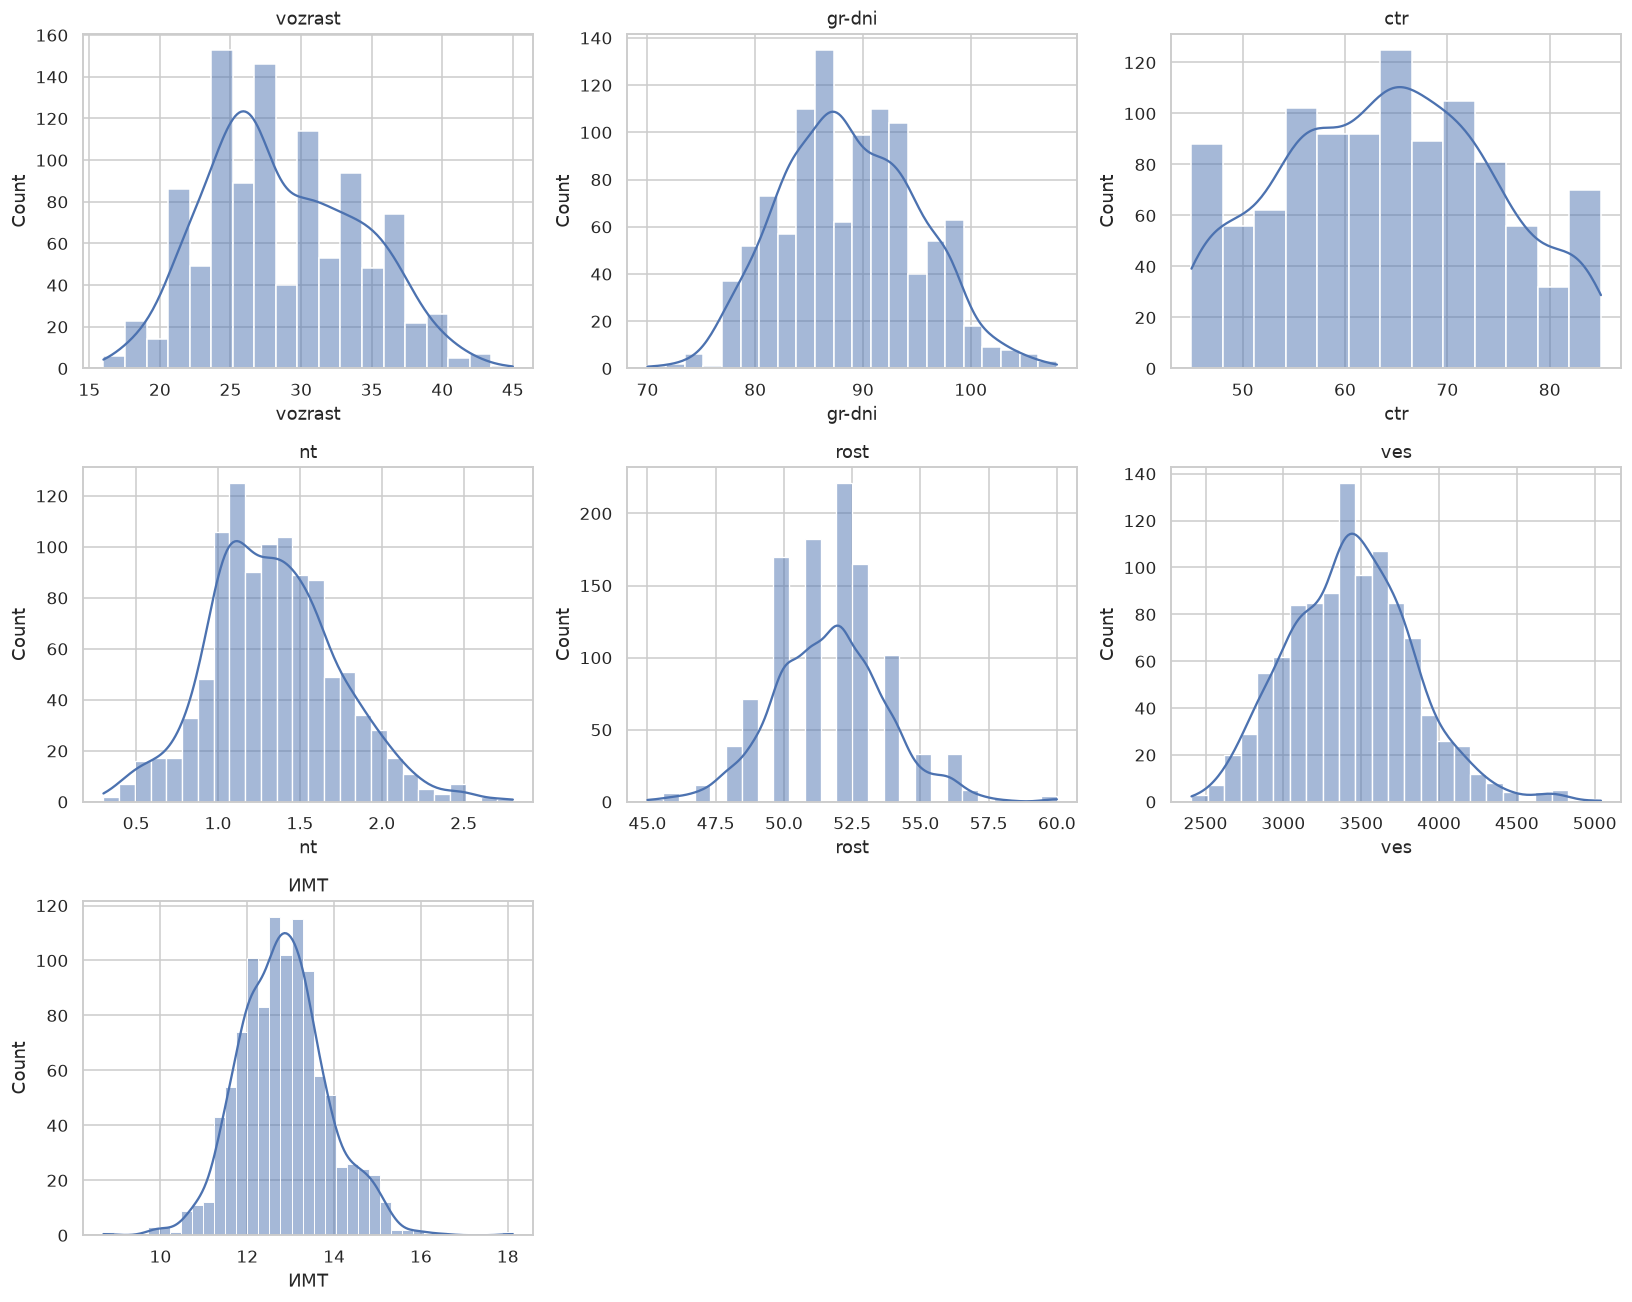

,показатель,n,mean,median,skew,excess,W,p,H0 нормальность отклонена
0,vozrast,1050,28.681905,28.000000,0.278528,-0.595901,0.980773,1.468350e-10,True
1,gr-dni,1050,88.764762,88.000000,0.163237,-0.349594,0.992675,4.659236e-05,True
2,ctr,1050,64.125714,64.000000,0.036253,-0.817104,0.977383,1.006609e-11,True
3,nt,1050,1.337333,1.300000,0.329712,0.303430,0.985847,1.495901e-08,True
4,rost,1050,51.698095,52.000000,0.230543,0.819221,0.972701,3.697210e-13,True
5,ves,1050,3435.779048,3430.000000,0.326097,0.385348,0.990988,4.890124e-06,True
6,ИМТ,1050,12.829898,12.801384,0.291300,0.944273,0.990336,2.160838e-06,True


In [3]:
normal = []
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for col, ax in zip(num, axes.flat):
    x = birth[col].dropna()
    sns.histplot(x, kde=True, ax=ax)
    ax.set_title(col)
    test = stats.shapiro(x)
    normal.append([col, len(x), x.mean(), x.median(), stats.skew(x, bias=False), stats.kurtosis(x, bias=False), test.statistic, test.pvalue])
for ax in axes.flat[len(num):]:
    ax.axis('off')
show('birth_normality')
normal = pd.DataFrame(normal, columns=['показатель', 'n', 'mean', 'median', 'skew', 'excess', 'W', 'p'])
normal['H0 нормальность отклонена'] = normal.p < 0.05
display(normal)

При нормальном распределении теоретические асимметрия и эксцесс равны 0, среднее и медиана совпадают. Выборочные оценки не обязаны быть точно нулевыми. Shapiro проверяет H0 о нормальности; при большом n он выявляет и небольшие отклонения. Визуализация и величина отклонений нужны вместе с p-value.

In [4]:
def holm(pvalues):
    p = np.asarray(pvalues)
    order = np.argsort(p)
    adjusted = np.empty(len(p))
    adjusted[order] = np.minimum(1, np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]))
    return adjusted

def compare_groups(frame, group, cols, a, b):
    rows = []
    for col in cols:
        x = frame.loc[frame[group].eq(a), col].dropna().to_numpy()
        y = frame.loc[frame[group].eq(b), col].dropna().to_numpy()
        t, p = stats.ttest_ind(x, y, equal_var=False)
        diff = x.mean() - y.mean()
        vx = x.var(ddof=1) / len(x)
        vy = y.var(ddof=1) / len(y)
        se = np.sqrt(vx + vy)
        dof = (vx + vy) ** 2 / (vx * vx / (len(x) - 1) + vy * vy / (len(y) - 1))
        margin = stats.t.ppf(0.975, dof) * se
        pooled = np.sqrt(((len(x) - 1) * x.var(ddof=1) + (len(y) - 1) * y.var(ddof=1)) / (len(x) + len(y) - 2))
        rows.append([col, len(x), len(y), x.mean(), y.mean(), diff, t, p, diff - margin, diff + margin, diff / pooled])
    r = pd.DataFrame(rows, columns=['показатель', 'n_A', 'n_B', 'mean_A', 'mean_B', 'A-B', 't', 'p', 'CI_low', 'CI_high', 'Cohen_d'])
    r['значимо без поправки'] = r.p < 0.05
    r['p_Holm'] = holm(r.p)
    r['вывод_0.05'] = np.where(r.p_Holm < 0.05, 'H0 отклонена', 'H0 не отклонена')
    return r
birth_tests = compare_groups(birth, 'pol(1-м, 0-д)', ['rost', 'ves', 'ИМТ'], 1, 0)
display(birth_tests)
birth_tests.to_csv(DATA / 'birth_welch.csv', index=False)

,показатель,n_A,n_B,mean_A,mean_B,A-B,t,p,CI_low,CI_high,Cohen_d,значимо без поправки,p_Holm,вывод_0.05
0,rost,577,473,52.001733,51.327696,0.674038,5.296915,1.441538e-07,0.424335,0.923740,0.327059,True,2.883075e-07,H0 отклонена
1,ves,577,473,3497.455806,3360.541226,136.914580,5.678143,1.764685e-08,89.599894,184.229266,0.347813,True,5.294054e-08,H0 отклонена
2,ИМТ,577,473,12.906159,12.736868,0.169291,2.704768,6.948251e-03,0.046473,0.292110,0.166819,True,6.948251e-03,H0 отклонена


Сравнение мальчики минус девочки:

**rost**: разность 0.674, 95% ДИ [0.424; 0.924], p=1.442e-07, p Holm=2.883e-07; есть статистические основания отвергнуть равенство средних.

**ves**: разность 136.915, 95% ДИ [89.600; 184.229], p=1.765e-08, p Holm=5.294e-08; есть статистические основания отвергнуть равенство средних.

**ИМТ**: разность 0.169, 95% ДИ [0.046; 0.292], p=0.006948, p Holm=0.006948; есть статистические основания отвергнуть равенство средних.

Группы независимы, дисперсии не приравниваются. Большой объём смягчает ненормальность для среднего, но независимость наблюдений и отсутствие семейной кластеризации требуют проверки по дизайну сбора. Значимость не равна клинической значимости.

In [5]:
display(Markdown('## Итоговый вывод'))
print(f"Всего {len(birth)} новорождённых: {(birth['pol(1-м, 0-д)'] == 1).sum()} мальчиков и {(birth['pol(1-м, 0-д)'] == 0).sum()} девочек.")
print('H0 о нормальности отклонена для:', ', '.join(normal.loc[normal.p < 0.05, 'показатель']))
for row in birth_tests.to_dict('records'):
    print(f"{row['показатель']}: средние {row['mean_A']:.3f} и {row['mean_B']:.3f}; t={row['t']:.4f}, p={row['p']:.6g}, p Holm={row['p_Holm']:.6g}; {row['вывод_0.05']}.")

## Итоговый вывод

Всего 1050 новорождённых: 577 мальчиков и 473 девочек.
H0 о нормальности отклонена для: vozrast, gr-dni, ctr, nt, rost, ves, ИМТ
rost: средние 52.002 и 51.328; t=5.2969, p=1.44154e-07, p Holm=2.88308e-07; H0 отклонена.
ves: средние 3497.456 и 3360.541; t=5.6781, p=1.76468e-08, p Holm=5.29405e-08; H0 отклонена.
ИМТ: средние 12.906 и 12.737; t=2.7048, p=0.00694825, p Holm=0.00694825; H0 отклонена.


## B Психологические показатели и t-тесты

### 2. Гипотезы и выбор критерия

H₀: средние значения показателя у юношей и девушек одинаковы. H₁: средние различаются. Уровень значимости α=0,05. Группы независимы; используем двусторонний t-тест Уэлча (`equal_var=False`). Парный тест не подходит, поскольку строки не являются повторными измерениями одних людей.

Номер учащегося и код профиля исключены из психологических шкал. Для каждого из 15 показателей приведены t, исходное p-value и вывод при α=0,05; отдельно добавлена поправка Holm на множественные проверки, 95% ДИ разности и Cohen d. Неотклонение H₀ не доказывает равенство групп.

In [6]:
def holm(pvalues):
    p = np.asarray(pvalues)
    order = np.argsort(p)
    adjusted = np.empty(len(p))
    adjusted[order] = np.minimum(1, np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]))
    return adjusted

def compare_groups(frame, group, cols, a, b):
    rows = []
    for col in cols:
        x = frame.loc[frame[group].eq(a), col].dropna().to_numpy()
        y = frame.loc[frame[group].eq(b), col].dropna().to_numpy()
        t, p = stats.ttest_ind(x, y, equal_var=False)
        diff = x.mean() - y.mean()
        vx = x.var(ddof=1) / len(x)
        vy = y.var(ddof=1) / len(y)
        se = np.sqrt(vx + vy)
        dof = (vx + vy) ** 2 / (vx * vx / (len(x) - 1) + vy * vy / (len(y) - 1))
        margin = stats.t.ppf(0.975, dof) * se
        pooled = np.sqrt(((len(x) - 1) * x.var(ddof=1) + (len(y) - 1) * y.var(ddof=1)) / (len(x) + len(y) - 2))
        rows.append([col, len(x), len(y), x.mean(), y.mean(), diff, t, p, diff - margin, diff + margin, diff / pooled])
    r = pd.DataFrame(rows, columns=['показатель', 'n_A', 'n_B', 'mean_A', 'mean_B', 'A-B', 't', 'p', 'CI_low', 'CI_high', 'Cohen_d'])
    r['значимо без поправки'] = r.p < 0.05
    r['p_Holm'] = holm(r.p)
    r['вывод_0.05'] = np.where(r.p_Holm < 0.05, 'H0 отклонена', 'H0 не отклонена')
    return r

### Психологические показатели

In [7]:
psy = pd.read_excel(DATA / 'Психологи.xlsx')
psy.columns = psy.columns.str.strip()
psy['пол'] = psy['пол'].str.strip().str.lower()
display(psy.head())
display(psy['пол'].value_counts())
display(psy.isna().sum())
psy_cols = [c for c in psy.select_dtypes('number').columns if c not in ['учащиеся', 'профиль ВУЗа']]
psy_tests = compare_groups(psy, 'пол', psy_cols, 'м', 'ж')
display(psy_tests.sort_values('p'))
normal_psy = []
for c in psy_cols:
    for g in ['м', 'ж']:
        x = psy.loc[psy['пол'].eq(g), c].dropna()
        normal_psy.append([c, g, len(x), stats.shapiro(x).pvalue])
display(pd.DataFrame(normal_psy, columns=['шкала', 'пол', 'n', 'p_Shapiro']))
psy_tests.to_csv(DATA / 'psychology_welch.csv', index=False)

,учащиеся,пол,класс,профиль ВУЗа,осведомленность,скрытые фигуры,пропущенные слова,арифметика,понятливость,исключение изображений,аналогии,числовые ряды,умозаключения,геометрическое сложение,заучивание слов,средний IQ,экстраверсия- интроверсия,нейротизм,средняя отметка
0,1,ж,гум,0,12,9,11,8,8,11,13,8,12,10,11,103,15,7,3.93
1,2,ж,гум,1,10,12,12,11,10,12,9,12,8,11,11,107,13,17,4.27
2,3,м,мат,1,11,8,9,11,11,12,9,11,9,11,8,100,10,19,3.87
3,4,ж,гум,0,14,12,14,13,13,9,9,9,12,11,12,116,13,11,4.57
4,5,ж,гум,0,12,12,9,10,9,12,5,10,3,11,9,93,16,8,4.14


пол
ж    23
м    23
Name: count, dtype: int64

учащиеся                     0
пол                          0
класс                        0
профиль ВУЗа                 0
осведомленность              0
скрытые фигуры               0
пропущенные слова            0
арифметика                   0
понятливость                 0
исключение  изображений      0
аналогии                     0
числовые ряды                0
умозаключения                0
геометрическое  сложение     0
заучивание слов              0
средний IQ                   0
экстраверсия- интроверсия    0
нейротизм                    0
средняя отметка              0
dtype: int64

,показатель,n_A,n_B,mean_A,mean_B,A-B,t,p,CI_low,CI_high,Cohen_d,значимо без поправки,p_Holm,вывод_0.05
12,экстраверсия- интроверсия,23,23,11.565217,14.608696,-3.043478,-3.444096,0.001313,-4.826926,-1.260030,-1.015608,True,0.019699,H0 отклонена
1,скрытые фигуры,23,23,9.043478,10.608696,-1.565217,-2.011319,0.050646,-3.135039,0.004604,-0.593106,False,0.709042,H0 не отклонена
3,арифметика,23,23,11.695652,10.695652,1.000000,1.668595,0.102715,-0.209826,2.209826,0.492042,False,1.000000,H0 не отклонена
13,нейротизм,23,23,12.826087,11.000000,1.826087,1.614516,0.113599,-0.453687,4.105861,0.476095,False,1.000000,H0 не отклонена
7,числовые ряды,23,23,10.434783,9.347826,1.086957,1.602253,0.116539,-0.281791,2.455704,0.472479,False,1.000000,H0 не отклонена
10,заучивание слов,23,23,9.173913,10.173913,-1.000000,-1.535506,0.132067,-2.313799,0.313799,-0.452796,False,1.000000,H0 не отклонена
14,средняя отметка,23,23,3.976957,4.151304,-0.174348,-1.489710,0.143474,-0.410253,0.061558,-0.439292,False,1.000000,H0 не отклонена
0,осведомленность,23,23,10.304348,11.260870,-0.956522,-1.473229,0.148103,-2.266581,0.353537,-0.434432,False,1.000000,H0 не отклонена
5,исключение изображений,23,23,9.304348,10.260870,-0.956522,-1.357282,0.182584,-2.382505,0.469461,-0.400241,False,1.000000,H0 не отклонена
9,геометрическое сложение,23,23,11.608696,10.608696,1.000000,1.337259,0.188207,-0.508315,2.508315,0.394336,False,1.000000,H0 не отклонена


,шкала,пол,n,p_Shapiro
0,осведомленность,м,23,0.154013
1,осведомленность,ж,23,0.454872
2,скрытые фигуры,м,23,0.198462
3,скрытые фигуры,ж,23,0.003562
4,пропущенные слова,м,23,0.557954
...,...,...,...,...
25,экстраверсия- интроверсия,ж,23,0.053863
26,нейротизм,м,23,0.187958
27,нейротизм,ж,23,0.877465
28,средняя отметка,м,23,0.323701


Минимальное p у шкалы «экстраверсия- интроверсия», максимальное — «средний IQ». Это сила статистического свидетельства, не размер различия: величина эффекта отдельно дана в Cohen d. После Holm значимых шкал 1 из 15. При малой выборке, ненормальности или порядковых шкалах выводы t-тестов требуют осторожности; группы могут различаться также по классу и профилю, поэтому причинный эффект пола не установлен.

### Итоговый вывод
Статистику и p-value показываем для каждой шкалы. Наиболее и наименее выраженные различия сравниваем по абсолютному стандартизованному эффекту Cohen d, чтобы шкалы с разными единицами были сопоставимы.

In [8]:
for label, idx in [('Сильнее всего', psy_tests.Cohen_d.abs().idxmax()), ('Слабее всего', psy_tests.Cohen_d.abs().idxmin())]:
    row = psy_tests.loc[idx]
    print(f"{label}: {row['показатель']}; средние юношей/девушек {row.mean_A:.3f}/{row.mean_B:.3f}; d={row.Cohen_d:.3f}; t={row.t:.4f}; p={row.p:.6g}.")
print('Значимые шкалы до поправки:', ', '.join(psy_tests.loc[psy_tests.p < 0.05, 'показатель']))
print('Значимые шкалы после Holm:', ', '.join(psy_tests.loc[psy_tests.p_Holm < 0.05, 'показатель']))

Сильнее всего: экстраверсия- интроверсия; средние юношей/девушек 11.565/14.609; d=-1.016; t=-3.4441; p=0.00131324.
Слабее всего: средний IQ; средние юношей/девушек 104.522/105.217; d=-0.049; t=-0.1657; p=0.86916.
Значимые шкалы до поправки: экстраверсия- интроверсия
Значимые шкалы после Holm: экстраверсия- интроверсия


## C Бонус Проверка нормальности Iris

### Бонус Iris Функция Gauss
H0: признак имеет нормальное распределение с оценёнными μ и σ; H1: распределение отличается. Критерий χ² Пирсона строится по равновероятным интервалам нормального распределения с крайними границами ±∞. Ожидаемая частота не меньше 5. Два параметра оценены по выборке, поэтому ddof=2 и число степеней свободы k−3. Применимость асимптотического приближения ограничена, особенно при малых выборках и округлении измерений.

,Ширина лепестка,Длина лепестка,Ширина чашелистика,Длина чашелистика
1,0.2,1.4,3.5,5.1
2,0.2,1.4,3.0,4.9
3,0.2,1.3,3.2,4.7
4,0.2,1.5,3.1,4.6
5,0.2,1.4,3.6,5.0


Ширина лепестка n= 150 mean= 1.1993333333333336 median= 1.3 skew= -0.1029667476489812 excess= -1.340603996612645
H0: нормальность; H1: не нормальность; χ²= 59.06666666666666 df= 5 p= 1.8946730414722948e-11 ; H0 отклонена


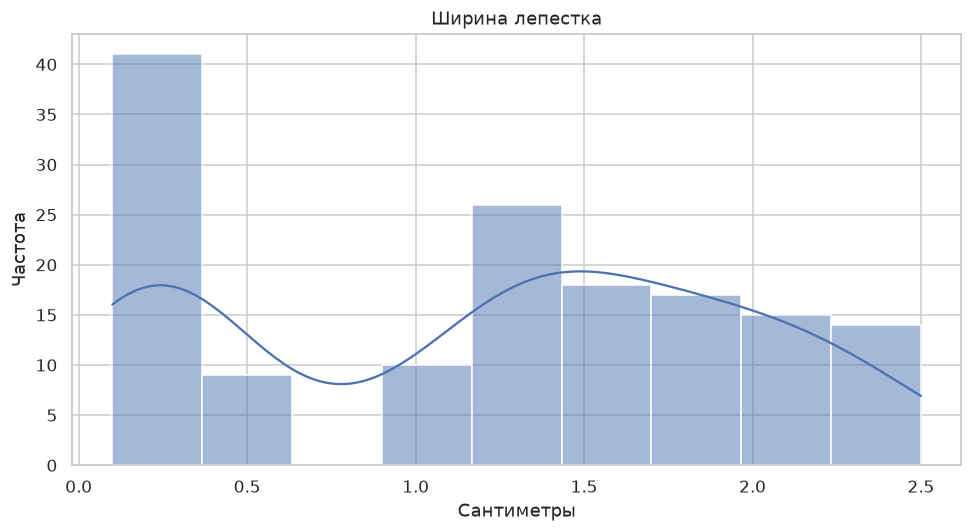

Длина лепестка n= 150 mean= 3.7580000000000005 median= 4.35 skew= -0.2748841797510128 excess= -1.4021034155217516
H0: нормальность; H1: не нормальность; χ²= 98.85333333333332 df= 5 p= 9.219114983995426e-20 ; H0 отклонена


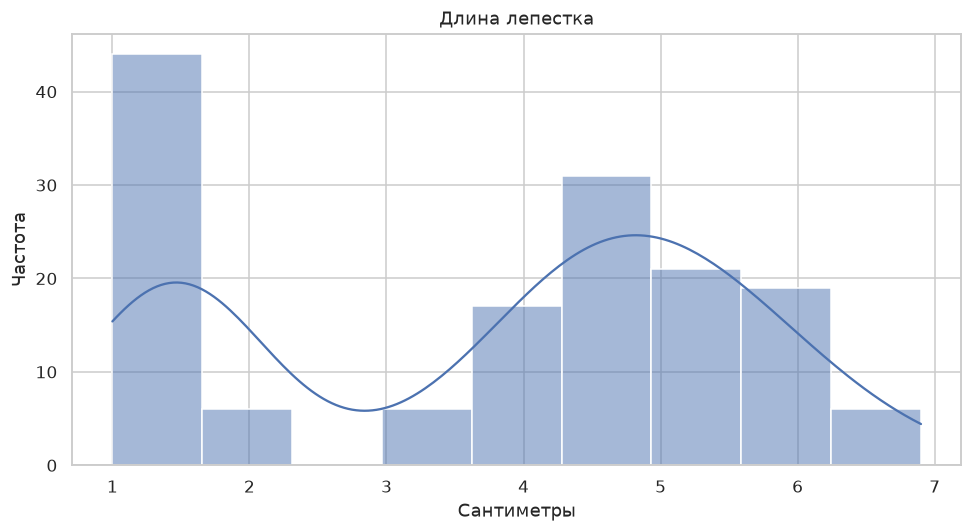

Ширина чашелистика n= 150 mean= 3.0573333333333337 median= 3.0 skew= 0.3189656647135998 excess= 0.2282490424681929
H0: нормальность; H1: не нормальность; χ²= 8.72 df= 5 p= 0.12076725712024744 ; H0 не отклонена


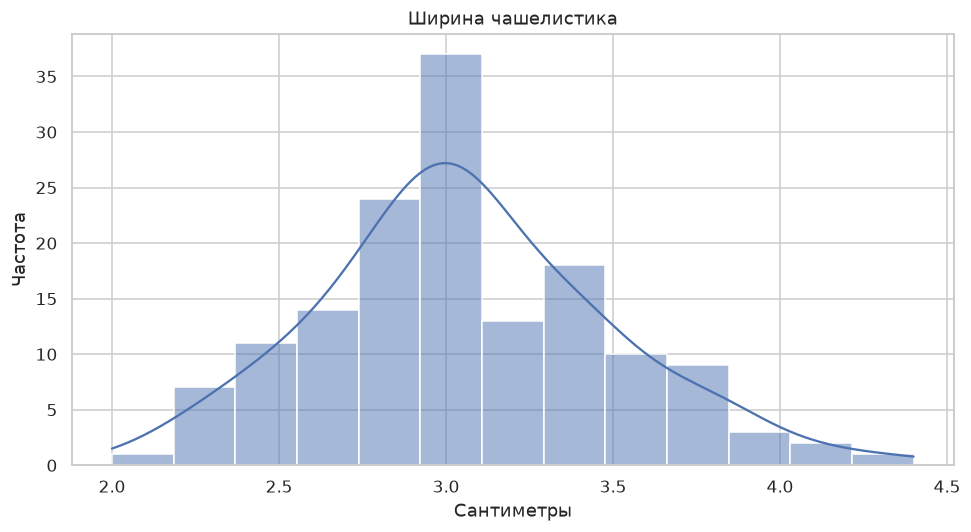

Длина чашелистика n= 150 mean= 5.843333333333334 median= 5.8 skew= 0.3149109566369729 excess= -0.5520640413156395
H0: нормальность; H1: не нормальность; χ²= 10.64 df= 5 p= 0.05900384824545067 ; H0 не отклонена


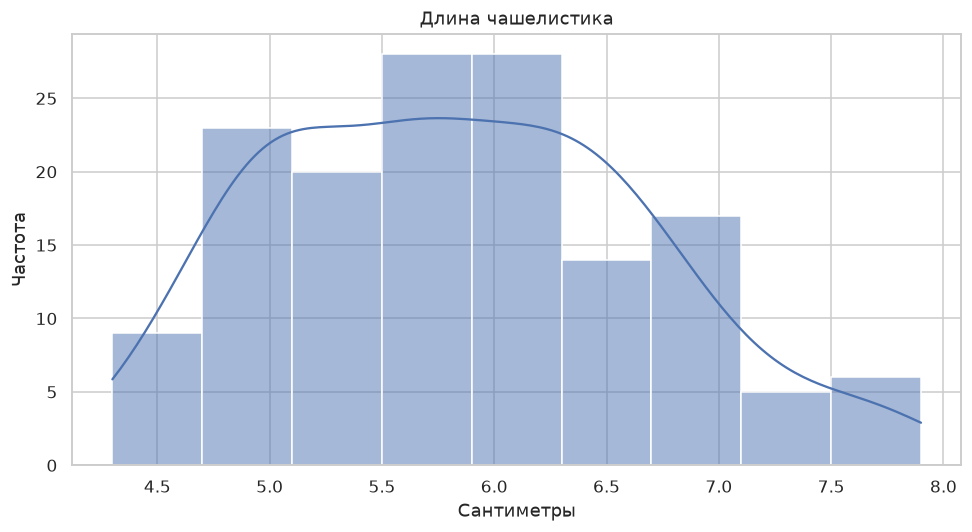

Ширина лепестка       1.894673e-11
Длина лепестка        9.219115e-20
Ширина чашелистика    1.207673e-01
Длина чашелистика     5.900385e-02
Name: p χ², dtype: float64

Минимальное p для: Длина лепестка
Длина лепестка Setosa n= 50 mean= 1.4620000000000002 median= 1.5 skew= 0.1063938996982434 excess= 1.0215761065826152
H0: нормальность; H1: не нормальность; χ²= 4.4 df= 2 p= 0.11080315836233386 ; H0 не отклонена


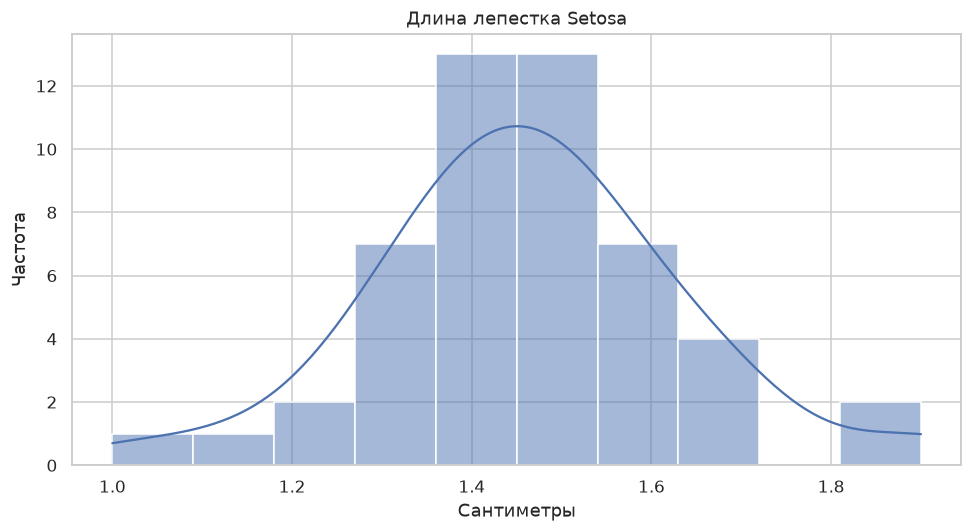

Длина лепестка Verginica n= 50 mean= 5.5520000000000005 median= 5.55 skew= 0.5494445890270053 excess= -0.1537785609504292
H0: нормальность; H1: не нормальность; χ²= 1.2000000000000002 df= 2 p= 0.5488116360940265 ; H0 не отклонена


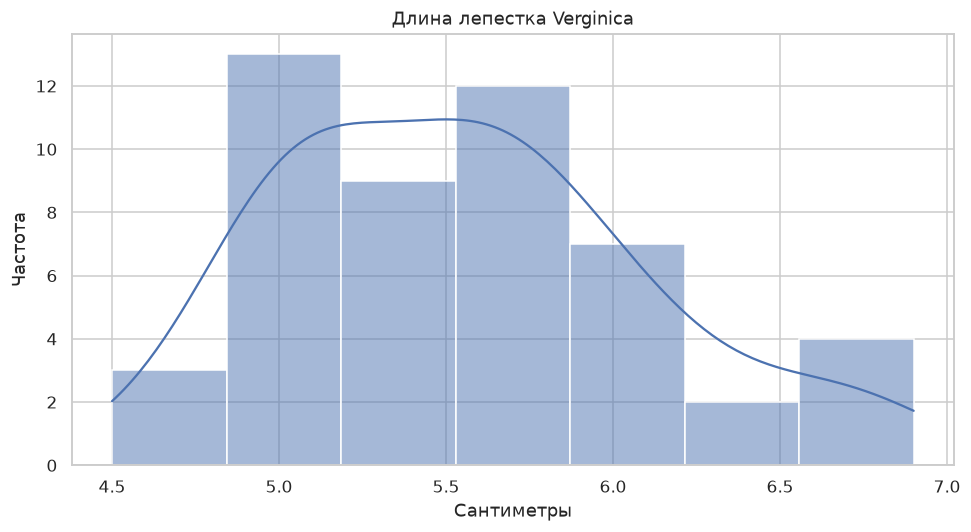

Длина лепестка Versicolor n= 50 mean= 4.26 median= 4.35 skew= -0.606507689490624 excess= 0.047903299627571005
H0: нормальность; H1: не нормальность; χ²= 3.8000000000000003 df= 2 p= 0.14956861922263504 ; H0 не отклонена


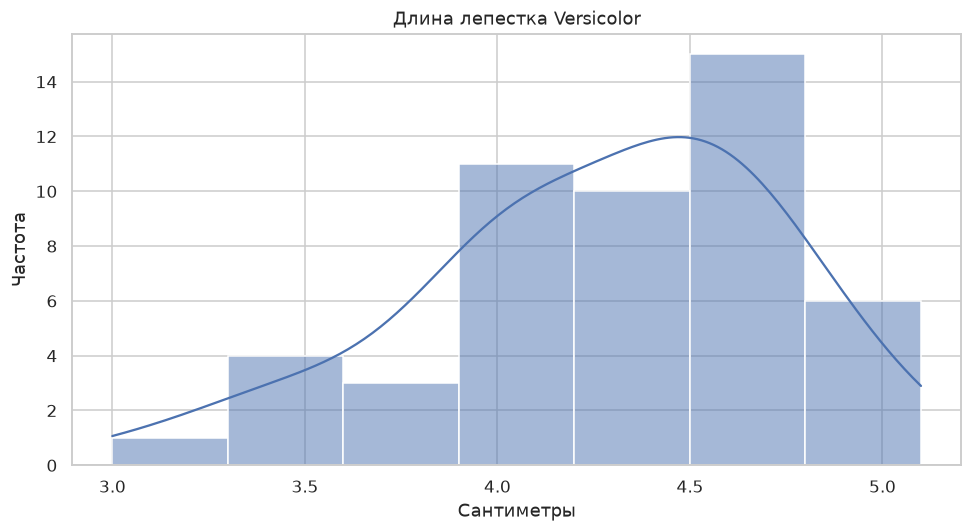

Длина лепестка мелкие Setosa n= 50 mean= 1.4620000000000002 median= 1.5 skew= 0.1063938996982434 excess= 1.0215761065826152
H0: нормальность; H1: не нормальность; χ²= 4.4 df= 2 p= 0.11080315836233386 ; H0 не отклонена


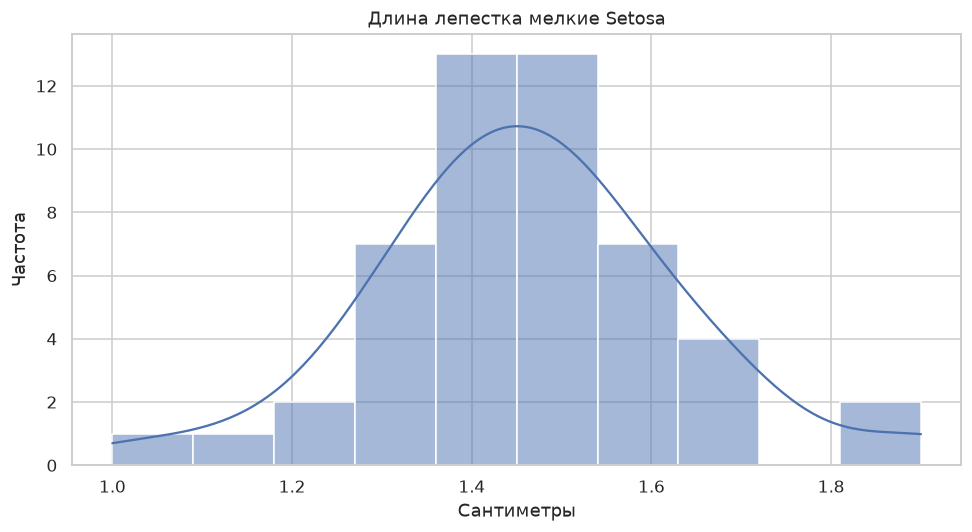

Длина лепестка крупные два сорта n= 100 mean= 4.906 median= 4.9 skew= 0.17107351966707676 excess= -0.32483353668775194
H0: нормальность; H1: не нормальность; χ²= 4.96 df= 5 p= 0.4207813477767336 ; H0 не отклонена


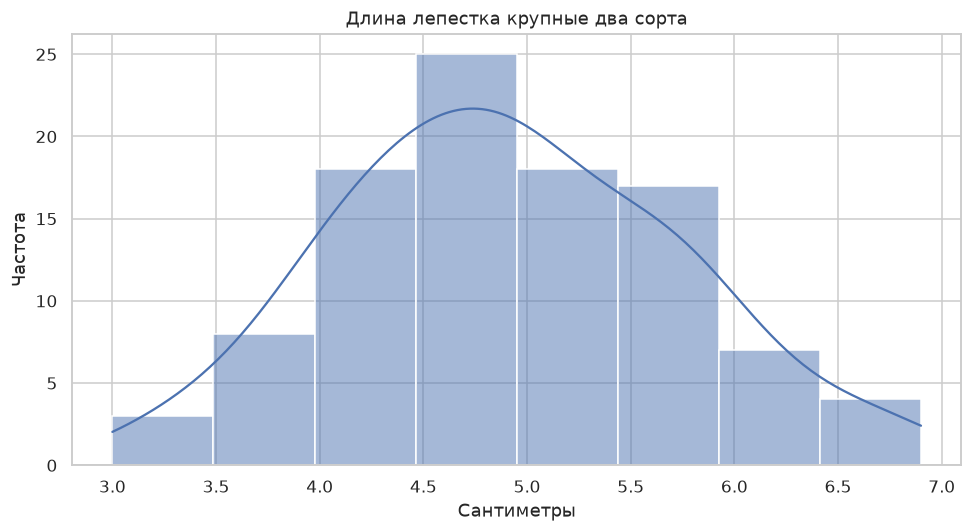

In [9]:
iris_raw = pd.read_excel(DATA / 'Iris.xlsx', sheet_name='Data')
iris_raw['Species_name'] = iris_raw['Species_name'].str.strip()
translations = {'Petal_width': 'Ширина лепестка', 'Petal_length': 'Длина лепестка', 'Sepal_width': 'Ширина чашелистика', 'Sepal_length': 'Длина чашелистика'}
iris = iris_raw.drop(columns=['Species_No', 'Species_name']).rename(columns=translations)
iris.index = np.arange(1, 151)
display(iris.head())

def Gauss(x, name):
    x = np.asarray(pd.Series(x).dropna(), dtype=float)
    n = len(x)
    k = min(8, n // 10)
    mu = x.mean()
    sigma = x.std(ddof=0)
    if k < 4 or sigma <= 0:
        raise ValueError('Недостаточно данных для χ² с двумя оценёнными параметрами')
    edges = stats.norm.ppf(np.linspace(0, 1, k + 1), loc=mu, scale=sigma)
    observed, _ = np.histogram(x, bins=edges)
    expected = np.full(k, n / k)
    chi, p = stats.chisquare(observed, expected, ddof=2)
    print(name, 'n=', n, 'mean=', mu, 'median=', np.median(x), 'skew=', stats.skew(x, bias=False), 'excess=', stats.kurtosis(x, bias=False))
    print('H0: нормальность; H1: не нормальность; χ²=', chi, 'df=', k - 3, 'p=', p, '; H0', 'отклонена' if p < 0.05 else 'не отклонена')
    sns.histplot(x, kde=True)
    plt.title(name)
    plt.xlabel('Сантиметры')
    plt.ylabel('Частота')
    show('iris_' + str(Gauss.counter))
    Gauss.counter += 1
    return p
Gauss.counter = 0
iris_p = {c: Gauss(iris[c], c) for c in iris.columns}
display(pd.Series(iris_p, name='p χ²'))
worst = min(iris_p, key=iris_p.get)
original = next((k for k, v in translations.items() if v == worst))
print('Минимальное p для:', worst)
species_p = {species: Gauss(part[original], worst + ' ' + species) for species, part in iris_raw.groupby('Species_name')}
small_p = Gauss(iris_raw.loc[iris_raw.Species_name.eq('Setosa'), original], worst + ' мелкие Setosa')
large_p = Gauss(iris_raw.loc[~iris_raw.Species_name.eq('Setosa'), original], worst + ' крупные два сорта')

### Общий вывод
Смесь сортов может быть ненормальной даже при близких к нормальным распределениях отдельных сортов. Функция проверяет каждый сорт и объединение двух крупных сортов отдельно; результаты приведены непосредственно над выводом. Неотклонение нормальности не означает её доказанности. Во всех сравнениях нужно учитывать размер эффекта, выбор метода и множественность проверок, а не только порог 0,05.

In [10]:
print('Выбранный признак:', worst)
for group, p in {**species_p, 'Мелкие (Setosa)': small_p, 'Крупные (два сорта)': large_p}.items():
    print(f"{group}: p={p:.6g}; H0 {('отклонена' if p < 0.05 else 'не отклонена')}.")

Выбранный признак: Длина лепестка
Setosa: p=0.110803; H0 не отклонена.
Verginica: p=0.548812; H0 не отклонена.
Versicolor: p=0.149569; H0 не отклонена.
Мелкие (Setosa): p=0.110803; H0 не отклонена.
Крупные (два сорта): p=0.420781; H0 не отклонена.
